# What is a FIFA 19 player worth?

This notebook predicts a player's market value in FIFA 19 from their age, ratings and attributes, and compares three models against a simple baseline. The data is the FIFA 19 complete player dataset from Kaggle (18,207 players scraped from sofifa.com), the same file used in lab 4.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
IMAGES = Path("images")
IMAGES.mkdir(exist_ok=True)

# colours and text styles shared by every chart
BLUE, GREY = "#2a78d6", "#b4b2ab"
INK, INK_SOFT = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d6d5d0", "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "text.color": INK, "axes.labelcolor": INK_SOFT, "xtick.color": INK_SOFT, "ytick.color": INK_SOFT,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10.5,
})

def save(fig, name):
    fig.savefig(IMAGES / name, dpi=120, bbox_inches="tight")

raw = pd.read_csv("../04-numpy-pandas-matplotlib/data.csv", index_col=0)
raw.shape

(18207, 88)

## Cleaning

Several columns are stored as text. Money looks like `€110.5M` or `€565K`, height like `5'7` (feet and inches) and weight like `159lbs`, so they have to be turned into numbers first.

In [2]:
def parse_money(text):
    """'€110.5M' -> 110500000.0, '€565K' -> 565000.0"""
    if pd.isna(text):
        return np.nan
    text = text.replace("€", "")
    multiplier = 1
    if text.endswith("M"):
        multiplier, text = 1_000_000, text[:-1]
    elif text.endswith("K"):
        multiplier, text = 1_000, text[:-1]
    return float(text) * multiplier


def parse_height(text):
    """5'7 -> centimetres"""
    if pd.isna(text):
        return np.nan
    feet, inches = text.split("'")
    return (int(feet) * 12 + int(inches)) * 2.54


def parse_weight(text):
    """'159lbs' -> kilograms"""
    if pd.isna(text):
        return np.nan
    return int(text.removesuffix("lbs")) * 0.4536


def position_group(position):
    if position == "GK":
        return "Goalkeeper"
    if position in {"CB", "LCB", "RCB", "LB", "RB", "LWB", "RWB"}:
        return "Defender"
    if position in {"ST", "LS", "RS", "CF", "LF", "RF", "LW", "RW"}:
        return "Forward"
    return "Midfielder"


df = raw[raw["Position"].notna()].copy()
df["Value"] = df["Value"].map(parse_money)
df["Height_cm"] = df["Height"].map(parse_height)
df["Weight_kg"] = df["Weight"].map(parse_weight)
# the column holds either a year ("2021") or a date ("Jun 30, 2019"); the year is always last
df["Contract_years_left"] = df["Contract Valid Until"].str[-4:].astype(float) - 2018
df["Left_footed"] = (df["Preferred Foot"] == "Left").astype(float)
df["Position_group"] = df["Position"].map(position_group)

print(f"{len(raw) - len(df)} players have no position, {(df['Value'] == 0).sum()} more have a value of €0")
df = df[df["Value"] > 0]
print(f"{len(df)} players left")
df[["Name", "Age", "Overall", "Value", "Height_cm", "Weight_kg", "Contract_years_left", "Position_group"]].head()

60 players have no position, 240 more have a value of €0
17907 players left


,Name,Age,Overall,Value,Height_cm,Weight_kg,Contract_years_left,Position_group
0,L. Messi,31,94,110500000.0,170.18,72.1224,3.0,Forward
1,Cristiano Ronaldo,33,94,77000000.0,187.96,83.0088,4.0,Forward
2,Neymar Jr,26,92,118500000.0,175.26,68.0400,4.0,Forward
3,De Gea,27,91,72000000.0,193.04,76.2048,2.0,Goalkeeper
4,K. De Bruyne,27,91,102000000.0,180.34,69.8544,5.0,Midfielder


## A first look

Market values are very skewed. Most players are worth less than €1M while a handful are worth more than €100M, and a model that minimises squared error would spend most of its effort on those few stars. The target is therefore the logarithm (base 10) of the value. On that scale, being 20% off counts the same for a €500K player as for a €50M one.

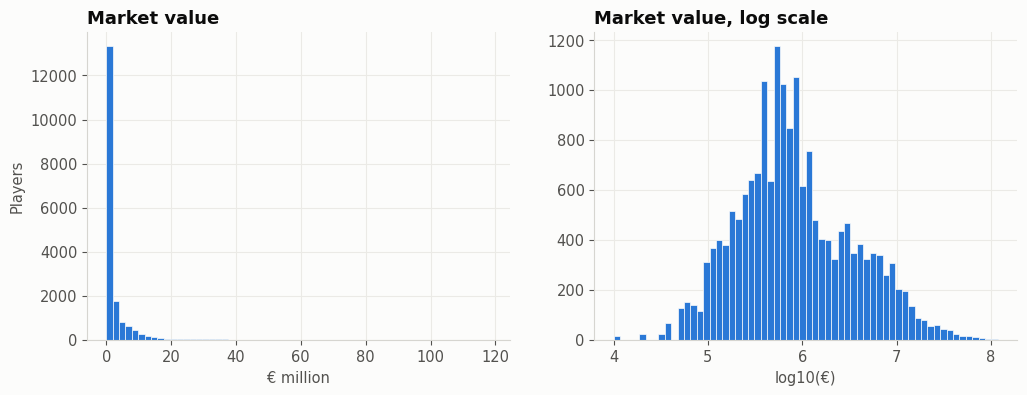

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["Value"] / 1e6, bins=60, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
axes[0].set_title("Market value")
axes[0].set_xlabel("€ million")
axes[0].set_ylabel("Players")
axes[1].hist(np.log10(df["Value"]), bins=60, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
axes[1].set_title("Market value, log scale")
axes[1].set_xlabel("log10(€)")
axes[1].xaxis.set_major_locator(mticker.MultipleLocator(1))
save(fig, "value_distribution.png")
plt.show()

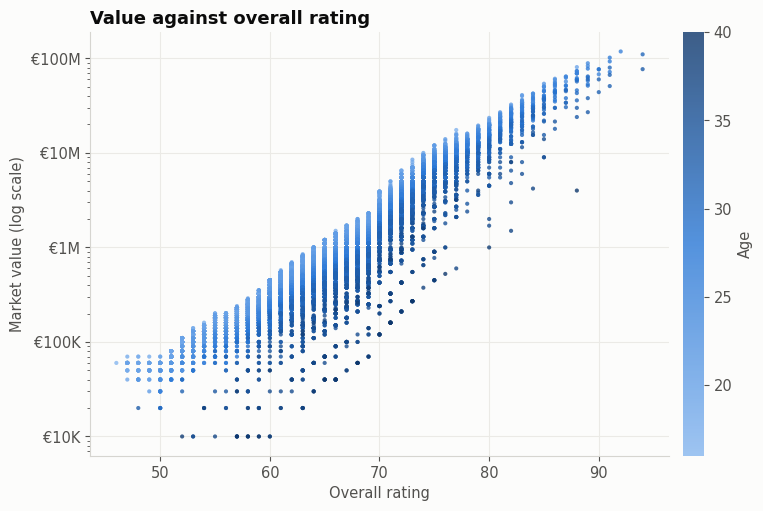

In [4]:
# one blue ramp, light for young players and dark for older ones
age_ramp = LinearSegmentedColormap.from_list("age", ["#86b6ef", "#2a78d6", "#0d366b"])
by_age = df.sort_values("Age")
fig, ax = plt.subplots(figsize=(9, 5.5))
points = ax.scatter(by_age["Overall"], by_age["Value"], c=by_age["Age"], cmap=age_ramp, s=9, alpha=0.8,
                    vmin=16, vmax=40, edgecolors="none")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(
    lambda v, _: f"€{v / 1e6:g}M" if v >= 1e6 else f"€{v / 1e3:g}K"))
ax.set_title("Value against overall rating")
ax.set_xlabel("Overall rating")
ax.set_ylabel("Market value (log scale)")
colorbar = fig.colorbar(points, ax=ax, pad=0.02)
colorbar.set_label("Age")
colorbar.outline.set_visible(False)
save(fig, "value_vs_overall.png")
plt.show()

Overall rating is clearly the strongest signal. On the log scale the points form an almost straight band, so every extra rating point multiplies the value by roughly the same factor, about 1.2 between ratings 50 and 90. At the same rating, older players (the darker points) sit lower. For players rated 75 to 78, the median value slides from about €11M at 21 to €6.5M at 30, then drops to under €1M by 36.

## Features, and what to leave out

The dataset also has `Wage` and `Release Clause`. The game sets both from the player's value, so using them would mean predicting the value from a copy of itself (this is called data leakage). They stay out, together with the per-position ratings (`LS`, `ST`, `CB` and so on), which are built from the attributes that are already included.

The features are age, overall and potential rating, international reputation, weak foot, skill moves, height, weight, preferred foot, years left on the contract, position group and the 34 individual attributes, from crossing to goalkeeper reflexes. 20% of the players are kept aside as a test set.

In [5]:
attributes = list(raw.loc[:, "Crossing":"GKReflexes"].columns)
numeric = ["Age", "Overall", "Potential", "International Reputation", "Weak Foot", "Skill Moves",
           "Height_cm", "Weight_kg", "Left_footed", "Contract_years_left"] + attributes

X = pd.concat([df[numeric], pd.get_dummies(df["Position_group"], prefix="Pos", dtype=float)], axis=1)
y = np.log10(df["Value"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"{X.shape[1]} features, {len(X_train)} training players, {len(X_test)} test players")
assert X.notna().all().all(), "no missing values are left after the cleaning above"

48 features, 14325 training players, 3582 test players


## Models

Four models are compared on the same split:

- a baseline that always predicts the median value, to show what "no model" scores;
- linear regression on standardised features;
- a random forest, which averages many decision trees trained on random samples of the data;
- gradient boosting (`HistGradientBoostingRegressor`), which builds trees one after another, each correcting the errors of the ones before.

Each model is first scored with 5-fold cross-validation on the training set: the training data is cut into five parts, and each part is used once for evaluation while the model trains on the other four. The test set is used only once, at the end.

The last column is the easiest one to read. It is the median of |predicted value / real value - 1| on the test set, so 0.15 would mean that for half of the players the estimate is within 15% of the real value.

In [6]:
models = {
    "Median baseline": DummyRegressor(strategy="median"),
    "Linear regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Random forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1,
                                           random_state=RANDOM_STATE),
    "Gradient boosting": HistGradientBoostingRegressor(max_iter=600, learning_rate=0.05,
                                                       random_state=RANDOM_STATE),
}

folds = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    cv_r2 = cross_val_score(model, X_train, y_train, cv=folds, scoring="r2")
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    relative_error = np.abs(10 ** (predicted - y_test) - 1)
    rows.append({
        "Model": name,
        "CV R² mean": cv_r2.mean(),
        "CV R² std": cv_r2.std(),
        "Test R²": r2_score(y_test, predicted),
        "Test MAE (log10)": mean_absolute_error(y_test, predicted),
        "Median relative error": np.median(relative_error),
    })

results = pd.DataFrame(rows).set_index("Model")
results.round(3)

,CV R² mean,CV R² std,Test R²,Test MAE (log10),Median relative error
Model,,,,,
Median baseline,-0.013,0.003,-0.017,0.474,0.750
Linear regression,0.971,0.002,0.971,0.076,0.137
Random forest,0.996,0.000,0.997,0.019,0.023
Gradient boosting,0.997,0.000,0.998,0.018,0.027


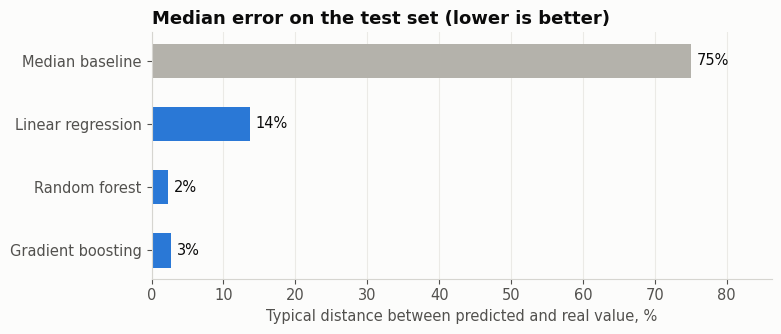

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.2))
names = results.index[::-1]
errors = results["Median relative error"][::-1] * 100
colors = [GREY if n == "Median baseline" else BLUE for n in names]
bars = ax.barh(names, errors, color=colors, height=0.55)
ax.bar_label(bars, labels=[f"{e:.0f}%" for e in errors], padding=4, color=INK)
ax.set_title("Median error on the test set (lower is better)")
ax.set_xlabel("Typical distance between predicted and real value, %")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, errors.max() * 1.15)
save(fig, "model_comparison.png")
plt.show()

Both tree models get within about 2 to 3% of the real value for half of the players and explain 99.7 to 99.8% of the variance of log(value). Random forest has the lower median error and gradient boosting the lower mean error, so they are practically tied. Linear regression explains 97% of the variance but is typically 14% off, because the relation between rating, age and value is curved and a straight line can't follow the sharp drop for older players.

In most projects, scores this high would mean a bug or a leak. Here the explanation is simpler: the game calculates market value from a few of the player's own numbers, and the models are rediscovering that calculation.

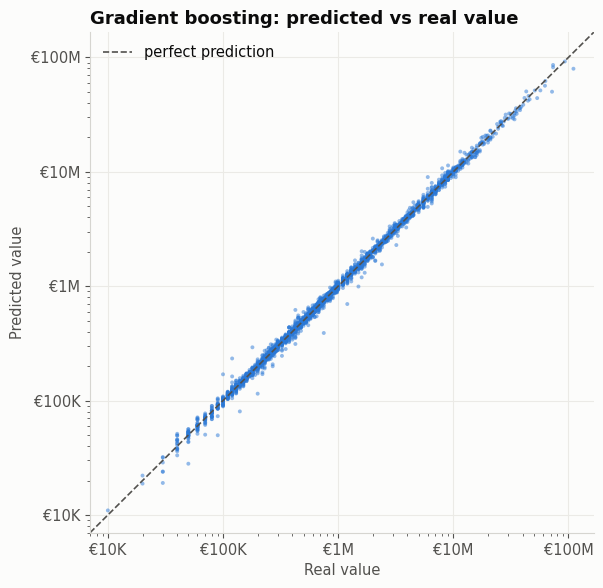

In [8]:
best = models["Gradient boosting"]
predicted = best.predict(X_test)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(10 ** y_test, 10 ** predicted, s=8, alpha=0.5, color=BLUE, edgecolors="none")
limits = [10 ** y.min() * 0.7, 10 ** y.max() * 1.4]
ax.plot(limits, limits, color=INK_SOFT, linewidth=1.2, linestyle="--", label="perfect prediction")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(limits)
ax.set_ylim(limits)
money = mticker.FuncFormatter(lambda v, _: f"€{v / 1e6:g}M" if v >= 1e6 else f"€{v / 1e3:g}K")
ax.xaxis.set_major_formatter(money)
ax.yaxis.set_major_formatter(money)
ax.set_title("Gradient boosting: predicted vs real value")
ax.set_xlabel("Real value")
ax.set_ylabel("Predicted value")
ax.legend(loc="upper left", frameon=False)
save(fig, "predicted_vs_actual.png")
plt.show()

## What drives the value

Permutation importance shuffles one feature at a time in the test set and measures how much R² drops. A big drop means the model leaned on that feature a lot.

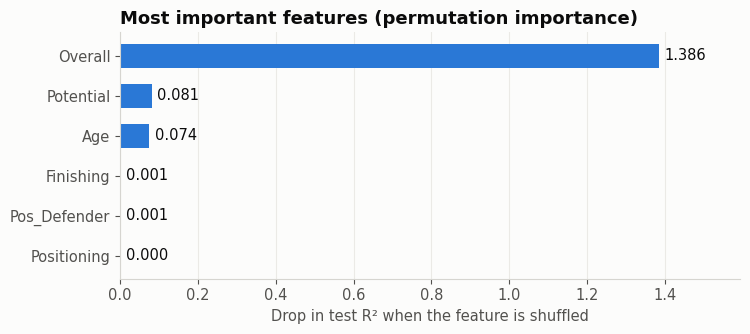

Overall          1.386
Potential        0.081
Age              0.074
Finishing        0.001
Pos_Defender     0.001
Positioning      0.000
BallControl      0.000
GKDiving         0.000
SlidingTackle    0.000
Pos_Forward      0.000
dtype: float64

In [9]:
importance = permutation_importance(best, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(importance.importances_mean, index=X.columns).sort_values(ascending=False)

top = importance.head(6)[::-1]
fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.barh(top.index, top.values, color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:.3f}" for v in top.values], padding=4, color=INK)
ax.set_title("Most important features (permutation importance)")
ax.set_xlabel("Drop in test R² when the feature is shuffled")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, top.max() * 1.15)
save(fig, "feature_importance.png")
plt.show()
importance.head(10).round(3)

Overall rating dominates, followed by potential and age. Shuffling a single attribute such as finishing or ball control barely changes the score, because the overall rating is computed from those attributes and already carries their effect. A drop larger than 1 is possible because R² turns negative once the predictions are worse than always guessing the mean.

If that's true, a model that sees only rating, potential, age and position should do as well as the full one.

In [10]:
few = ["Overall", "Potential", "Age", "Pos_Goalkeeper", "Pos_Defender", "Pos_Midfielder", "Pos_Forward"]
small = HistGradientBoostingRegressor(max_iter=600, learning_rate=0.05, random_state=RANDOM_STATE)
small.fit(X_train[few], y_train)
small_predicted = small.predict(X_test[few])
print(f"Overall, potential, age and position only: test R² {r2_score(y_test, small_predicted):.3f}, "
      f"median error {np.median(np.abs(10 ** (small_predicted - y_test) - 1)):.1%}")

Overall, potential, age and position only: test R² 0.998, median error 2.6%


It does: test R² 0.998 and a median error of 2.6%, against 2.7% with all 48 features. Once the overall rating is known, the 34 attributes add nothing.

## Bargains and overpriced players

Here every player gets a prediction from a model that never saw them during training (5-fold `cross_val_predict` over the whole dataset). The tables list players worth at least €5M whose real value is furthest from the estimate.

In [11]:
out_of_fold = cross_val_predict(models["Gradient boosting"], X, y, cv=folds)
gaps = df[["Name", "Club", "Age", "Overall", "Potential", "Position"]].copy()
gaps["Value €M"] = df["Value"] / 1e6
gaps["Predicted €M"] = 10 ** out_of_fold / 1e6
gaps["Real / predicted"] = gaps["Value €M"] / gaps["Predicted €M"]
big = gaps[gaps["Value €M"] >= 5]

print("Worth more in the game than the model expects")
display(big.sort_values("Real / predicted", ascending=False).head(8).round(2))
print("Worth less in the game than the model expects")
display(big.sort_values("Real / predicted").head(8).round(2))

Worth more in the game than the model expects


,Name,Club,Age,Overall,Potential,Position,Value €M,Predicted €M,Real / predicted
548,A. Mirante,Roma,34,80,80,GK,6.0,3.97,1.51
551,Moyá,Real Sociedad,34,80,80,GK,6.0,4.01,1.50
0,L. Messi,FC Barcelona,31,94,94,RF,110.5,74.05,1.49
3,De Gea,Manchester United,27,91,93,GK,72.0,49.17,1.46
719,L. López,Racing Club,35,79,79,LS,6.0,4.23,1.42
40,S. Handanovič,Inter,33,88,88,GK,30.0,22.33,1.34
1763,A. Meret,Napoli,21,75,89,GK,12.0,9.03,1.33
513,Bruno,Villarreal CF,34,80,80,CM,7.0,5.27,1.33


Worth less in the game than the model expects


,Name,Club,Age,Overall,Potential,Position,Value €M,Predicted €M,Real / predicted
109,Z. Ibrahimović,LA Galaxy,36,85,85,RS,14.0,21.34,0.66
108,Pepe,Beşiktaş JK,35,85,85,RCB,9.0,12.64,0.71
223,D. De Rossi,Roma,34,83,83,RDM,8.0,10.82,0.74
411,Joaquín,Real Betis,36,81,81,LS,6.0,8.07,0.74
224,Pepe Reina,Milan,35,83,83,GK,6.0,7.96,0.75
102,Naldo,FC Schalke 04,35,85,85,CB,9.0,11.71,0.77
76,Iniesta,Vissel Kobe,34,86,86,LF,21.5,27.79,0.77
399,A. Valencia,Manchester United,32,81,81,RM,10.0,12.91,0.77


The misses follow a pattern. Highly rated players aged 32 to 36, such as Ibrahimović, Pepe, De Rossi and Iniesta, are worth less in the game than predicted, because value falls steeply with age and there are few players like them to learn that curve from. At the top, Messi and De Gea are worth more than predicted: tree models can't predict beyond the values they saw in training, and almost nobody else is worth that much. Several veteran goalkeepers (Mirante, Moyá, Handanovič) are also valued higher than expected, although Pepe Reina, 35, goes the other way.

## Summary

- A FIFA 19 player's market value can be predicted from overall rating, potential, age and position with a median error of about 3%.
- Linear regression reaches R² 0.97 but is typically 14% off, because the relation is curved.
- Wage and release clause were left out on purpose, since the game derives both from the value.
- The biggest misses are veterans, whose value falls faster than the model learns, and the most expensive players, whom tree models can't extrapolate to.